<a href="https://colab.research.google.com/github/Balkrishnakc17/Numerical-Methods/blob/main/US_Mid_Term.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Prompt:

I want to vibe code a regression model with synthetic data based on U.S. midterm elections. I want to use voter turnout, unemployment rate, presidential approval rating, campaign spending, previous presidential election results, past midterm election performance of the president's party, and previous House and Senate seats as prediction variables. Generate synthetic data, build and evaluate the regression model, and visualize the results.

--- First 5 Rows of Synthetic Dataset ---
   Voter_Turnout  Unemployment_Rate  Presidential_Approval  Campaign_Spending  \
0      42.490802           3.220004              54.260949         146.513549   
1      54.014286           7.454873              37.524199         578.219168   
2      49.639879           5.200492              39.848861         586.571609   
3      46.973170           6.559995              61.956626         673.686911   
4      38.120373           9.352965              53.192872         753.482200   

   Prev_Pres_Result  Past_Midterm_Perf  Prev_House_Seats  Prev_Senate_Seats  \
0         -3.453142          -5.091914               204                 52   
1          8.538294         -13.195182               217                 49   
2          2.578786         -24.523619               227                 48   
3          7.396862           0.689751               241                 52   
4         -0.199256          -5.763441               221                 50 

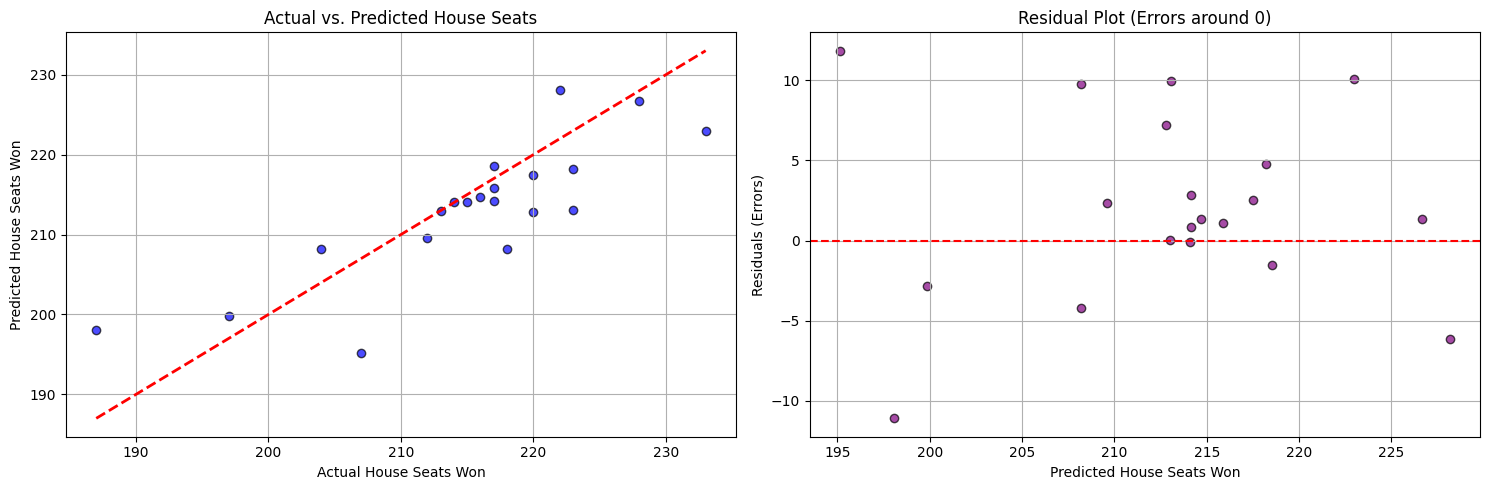

In [1]:
# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# We will use Linear Regression as our model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Set random seed for reproducibility
np.random.seed(42)
num_samples = 100

# Step 2: Generate synthetic dataset
# Let's generate realistic ranges for each requested variable:
# 1. Voter turnout (percentage, e.g., 35% to 55%)
voter_turnout = np.random.uniform(35, 55, num_samples)

# 2. Unemployment rate (percentage, e.g., 3% to 10%)
unemployment_rate = np.random.uniform(3, 10, num_samples)

# 3. Presidential approval rating (percentage, e.g., 35% to 65%)
presidential_approval = np.random.uniform(35, 65, num_samples)

# 4. Campaign spending (in millions of USD, e.g., $100M to $1000M)
campaign_spending = np.random.uniform(100, 1000, num_samples)

# 5. Previous presidential election result (margin of victory for president's party, e.g., -5% to 10%)
prev_pres_result = np.random.uniform(-5, 10, num_samples)

# 6. Past midterm election performance of the president's party (change in seats in previous midterm, e.g., -40 to +10)
past_midterm_perf = np.random.uniform(-40, 10, num_samples)

# 7. Number of House seats previously held by the president's party (e.g., 200 to 240 out of 435)
prev_house_seats = np.random.randint(200, 245, num_samples)

# 8. Number of Senate seats previously held by the president's party (e.g., 45 to 55 out of 100)
prev_senate_seats = np.random.randint(45, 56, num_samples)

# Let's define the Target variable: 'house_seats_won' (The number of House seats won in this midterm election)
# We'll construct a realistic relationship where presidential approval and previous seats strongly influence the outcome
# House seats won = baseline + coef1*approval - coef2*unemployment + coef3*prev_house_seats + random noise
noise = np.random.normal(0, 5, num_samples)
house_seats_won = (
    50
    + 0.8 * presidential_approval
    - 1.5 * unemployment_rate
    + 0.6 * prev_house_seats
    + 0.05 * prev_pres_result
    + noise
).astype(int)

# Create a DataFrame
df = pd.DataFrame({
    'Voter_Turnout': voter_turnout,
    'Unemployment_Rate': unemployment_rate,
    'Presidential_Approval': presidential_approval,
    'Campaign_Spending': campaign_spending,
    'Prev_Pres_Result': prev_pres_result,
    'Past_Midterm_Perf': past_midterm_perf,
    'Prev_House_Seats': prev_house_seats,
    'Prev_Senate_Seats': prev_senate_seats,
    'House_Seats_Won': house_seats_won
})

print("--- First 5 Rows of Synthetic Dataset ---")
print(df.head())

# Step 3: Split data into features (X) and target (y)
X = df.drop(columns=['House_Seats_Won'])
y = df['House_Seats_Won']

# Split into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 4: Build and Train the Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# Step 5: Evaluate the Model
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n--- Model Performance ---")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared (R2) Score: {r2:.2f}")

# Print coefficients to see feature importance
coefficients = pd.DataFrame({'Variable': X.columns, 'Coefficient': model.coef_})
print("\n--- Model Coefficients ---")
print(coefficients.sort_values(by='Coefficient', ascending=False))

# Step 6: Create Graphs showing the results
plt.figure(figsize=(15, 5))

# Subplot 1: Actual vs Predicted values
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred, color='blue', alpha=0.7, edgecolors='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual House Seats Won')
plt.ylabel('Predicted House Seats Won')
plt.title('Actual vs. Predicted House Seats')
plt.grid(True)

# Subplot 2: Residual Plot
residuals = y_test - y_pred
plt.subplot(1, 2, 2)
plt.scatter(y_pred, residuals, color='purple', alpha=0.7, edgecolors='k')
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted House Seats Won')
plt.ylabel('Residuals (Errors)')
plt.title('Residual Plot (Errors around 0)')
plt.grid(True)

plt.tight_layout()
plt.show()